домашнее задание 2 по cnn. берём датасет с мрт мозга, в нём 4 класса: glioma, meningioma, notumor, pituitary. план такой: смотрим данные, обучаем свою cnn, обучаем предобученный resnet18, сравниваем результаты.

установила библиотеку kagglehub, чтобы скачать датасет с kaggle

In [1]:
%pip install kagglehub --quiet

подключила все нужные библиотеки для работы с файлами, массивами, картинками, графиками, нейросетями на pytorch и метриками из sklearn, зафиксировала seed 42, чтобы результаты можно было повторить.

в выводе видно, что обучение будет идти на видеокарте (cuda), а не на процессоре

In [2]:
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.11.0+cu130


скачала датасет и сохранила путь к нему в переменную path. потом вывела структуру папок, чтобы убедиться, что внутри есть папки training и testing, а в них лежат папки с классами.

в главной папке brain-tumor-mri-dataset лежат две папки, Training для обучения и Testing для финальной проверки.

In [3]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level < 2:
        print("  " * level + os.path.basename(root) + "/", f"({len(files)} files)" if files else "")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset
brain-tumor-mri-dataset/ 
  Training/ 
  Testing/ 


задала размер картинок 128 на 128, названия классов узнала по названиям папок внутри training. написала функцию load_folder, которая проходит по всем папкам классов, открывает каждую картинку, переводит её в rgb, меняет размер и складывает в массив вместе с названием класса, загрузила обучающую и тестовую выборки целиком, без ограничения числа картинок.

вывод показывает, что в датасете 4 класса. glioma, meningioma и pituitary это три вида опухолей, а notumor снимок без опухоли. классы идут по алфавиту, тк я использовала sorted.

в обучающем пуле 5600 картинок, размер 128 на 128 пикселей и 3 цветовых канала. в тестовой выборке 1600 картинок такого же размера. из 5600 картинок я выделю 20 процентов на валидацию.

In [4]:
IMG_SIZE = 128
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        if per_class is not None:
            files = files[:per_class]
        for name in files:
            try:
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

X_train_all, y_train_all = load_folder(TRAIN_DIR)
X_test,      y_test      = load_folder(TEST_DIR)

print("Train pool:", X_train_all.shape, "Test:", X_test.shape)

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train pool: (5600, 128, 128, 3) Test: (1600, 128, 128, 3)


сначала нарисовала по две картинки каждого класса, чтобы увидеть, как выглядят данные. потом построила столбчатые диаграммы с количеством картинок в каждом классе для train и test, проверила, что классы сбалансированы.

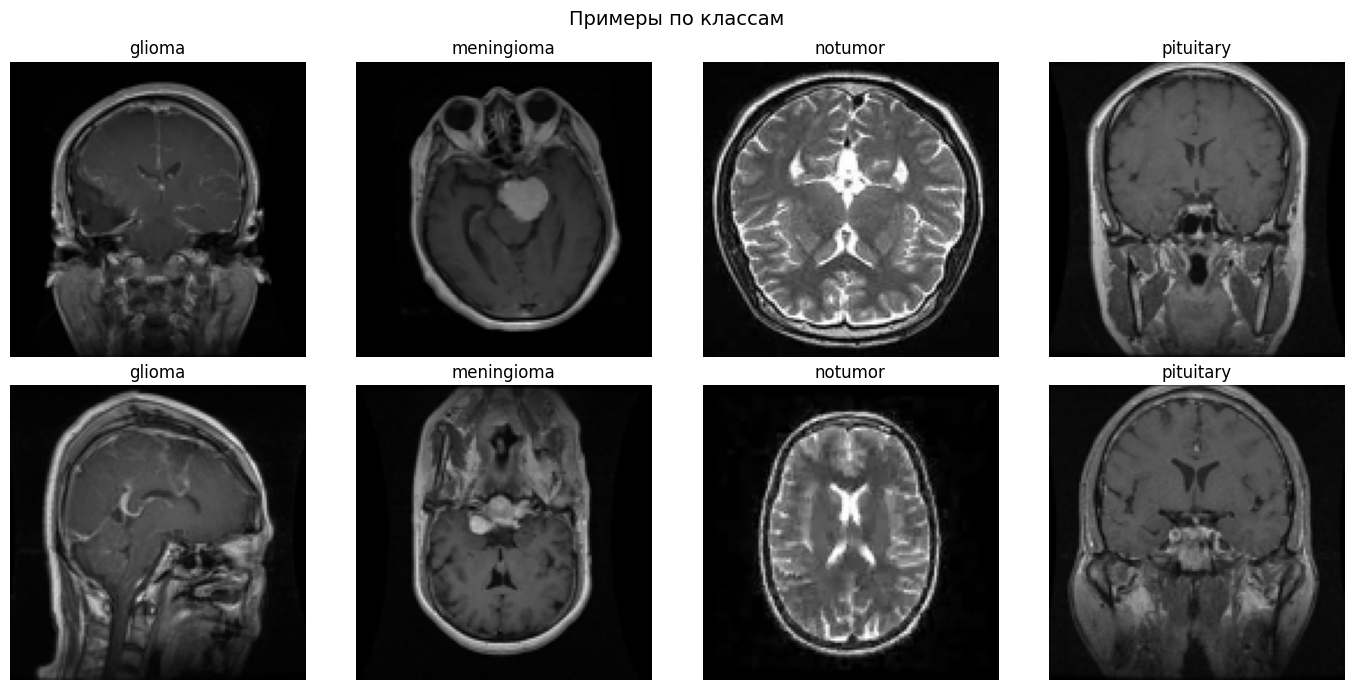

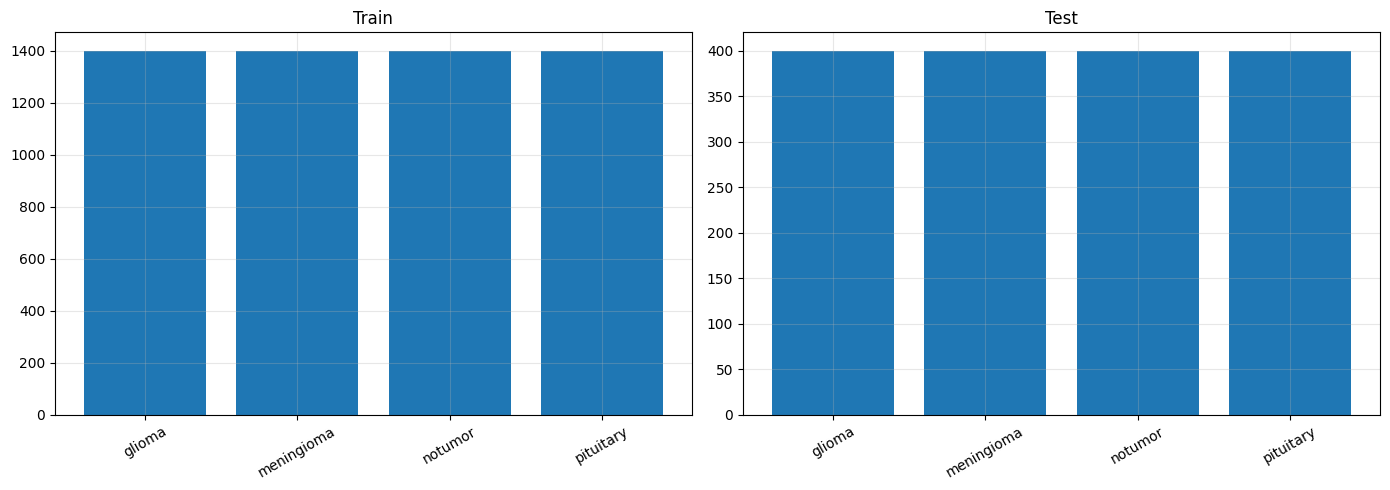

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r, cls in enumerate(classes[:4]):
    idxs = np.where(y_train_all == cls)[0][:2]
    for c, idx in enumerate(idxs):
        ax = axes[c, r]
        ax.imshow(X_train_all[idx]); ax.set_title(cls); ax.axis("off")
plt.suptitle("Примеры по классам", fontsize=14)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    ax.bar(u, c); ax.set_title(ttl); ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

перевела названия классов в числа 0, 1, 2 и 3, тк нейросеть работает с числами. разделила обучающие данные на train и val в пропорции 80 на 20 с сохранением долей классов. val нужна, чтобы следить за качеством во время обучения, а test оставила для финальной проверки. посчитала среднее и стандартное отклонение по train и использовала их для нормализации. для train добавила аугментации, отражение и небольшой поворот, чтобы модель меньше переобучалась. для val и test аугментаций не делала. создала класс dataset, который выдаёт картинку и её метку, и dataloader, которые подают данные порциями по 64 картинки.

In [6]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print("Классы:", class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc      = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.2, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2)).astype(np.float32)
std  = X_train_f.std(axis=(0, 1, 2)).astype(np.float32)
print("mean:", mean, "std:", std)

train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 64
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Классы: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Train: 4480, Val: 1120, Test: 1600
mean: [0.14160526 0.14160527 0.14164548] std: [0.17598583 0.17598517 0.17602508]


собрала свою сеть из четырёх блоков, в каждом свёртка, batchnorm, relu и maxpool. после блоков вытянула признаки в вектор и пропустила их через два полносвязных слоя. между ними поставила dropout, чтобы сеть не переобучалась. на выходе получается 4 числа, по одному на каждый класс. в конце проверила на случайных данных, что форма выхода правильная.

In [7]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        #блок 1: 3 -> 32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        #блок 2: 32 -> 64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        #блок 3: 64 -> 128
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        #блок 4: 128 -> 128
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        #128 -> 64 -> 32 -> 16 -> 8 после 4 MaxPool
        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

#проверка формы выхода
_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
with torch.no_grad():
    print(_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)

torch.Size([2, 4])


написала три функции. train_one_epoch делает одну эпоху обучения, модель предсказывает, считается ошибка, считаются градиенты и обновляются веса. evaluate оценивает модель без обучения и возвращает loss, accuracy и предсказания. fit запускает обучение на несколько эпох, печатает результаты каждой эпохи и сохраняет историю. внутри добавила уменьшение learning rate, если качество перестаёт расти, и раннюю остановку. в конце функция возвращает веса лучшей эпохи.

In [8]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss","val_loss","train_acc","val_acc","time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

создала свою сеть и обучила её с нуля, максимум 15 эпох с learning rate 0.001. результаты сохранила в hist_cnn.

признаков переобучения нет. точность на val почти всё время была близка к точности на train

In [9]:
cnn_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=15, lr=1e-3, weight_decay=1e-5,
               patience=4, title="SimpleCNN")

[SimpleCNN] Ep 01/15 | train loss 1.1617 acc 0.5953 | val loss 0.6784 acc 0.7116 | lr 1.00e-03 | 7.6s
[SimpleCNN] Ep 02/15 | train loss 0.6082 acc 0.7554 | val loss 0.6047 acc 0.7598 | lr 1.00e-03 | 7.1s
[SimpleCNN] Ep 03/15 | train loss 0.5340 acc 0.7868 | val loss 0.4960 acc 0.8107 | lr 1.00e-03 | 7.1s
[SimpleCNN] Ep 04/15 | train loss 0.4890 acc 0.7991 | val loss 0.5471 acc 0.7661 | lr 1.00e-03 | 7.7s
[SimpleCNN] Ep 05/15 | train loss 0.4271 acc 0.8304 | val loss 0.3921 acc 0.8598 | lr 1.00e-03 | 7.0s
[SimpleCNN] Ep 06/15 | train loss 0.3879 acc 0.8549 | val loss 0.3415 acc 0.8616 | lr 1.00e-03 | 7.1s
[SimpleCNN] Ep 07/15 | train loss 0.3490 acc 0.8658 | val loss 0.3187 acc 0.8750 | lr 1.00e-03 | 7.1s
[SimpleCNN] Ep 08/15 | train loss 0.3438 acc 0.8741 | val loss 0.3166 acc 0.8786 | lr 1.00e-03 | 7.0s
[SimpleCNN] Ep 09/15 | train loss 0.3155 acc 0.8828 | val loss 0.3831 acc 0.8321 | lr 1.00e-03 | 7.0s
[SimpleCNN] Ep 10/15 | train loss 0.3016 acc 0.8846 | val loss 0.3309 acc 0.8777 |

взяла resnet18, предобученную на imagenet. последний слой заменила на новый с 4 выходами под классы. обучила всю сеть целиком, с меньшим learning rate 0.0003, потому что веса в ней уже были хорошие. результаты сохранила в hist_resnet.

In [10]:
def build_resnet18(num_classes, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(NUM_CLASSES, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 126MB/s]


[ResNet18] Ep 01/10 | train loss 0.2922 acc 0.8884 | val loss 0.1977 acc 0.9295 | lr 3.00e-04 | 8.6s
[ResNet18] Ep 02/10 | train loss 0.1102 acc 0.9600 | val loss 0.1605 acc 0.9437 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 03/10 | train loss 0.0675 acc 0.9770 | val loss 0.1505 acc 0.9527 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 04/10 | train loss 0.0612 acc 0.9817 | val loss 0.1042 acc 0.9723 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 05/10 | train loss 0.0444 acc 0.9837 | val loss 0.1600 acc 0.9437 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 06/10 | train loss 0.0588 acc 0.9810 | val loss 0.1756 acc 0.9268 | lr 3.00e-04 | 8.3s
[ResNet18] Ep 07/10 | train loss 0.0382 acc 0.9864 | val loss 0.0891 acc 0.9732 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 08/10 | train loss 0.0298 acc 0.9906 | val loss 0.0784 acc 0.9777 | lr 3.00e-04 | 8.3s
[ResNet18] Ep 09/10 | train loss 0.0218 acc 0.9931 | val loss 0.0695 acc 0.9786 | lr 3.00e-04 | 8.4s
[ResNet18] Ep 10/10 | train loss 0.0201 acc 0.9924 | val loss 0.1906 acc 0.9437 | lr 3.00e-

написала функцию plot_histories и вызвала её для обеих моделей. она строит три графика рядом, loss, accuracy и время одной эпохи. пунктирные линии показывают train, сплошные показывают val. у каждой модели свой цвет. по графикам я посмотрела, как учились модели, было ли переобучение и какая работает быстрее

resnet18 учится и быстрее и лучше. за 10 эпох она достигла качества, до которого simplecnn не дошла и за 15, стало только чуть большее время эпохи.

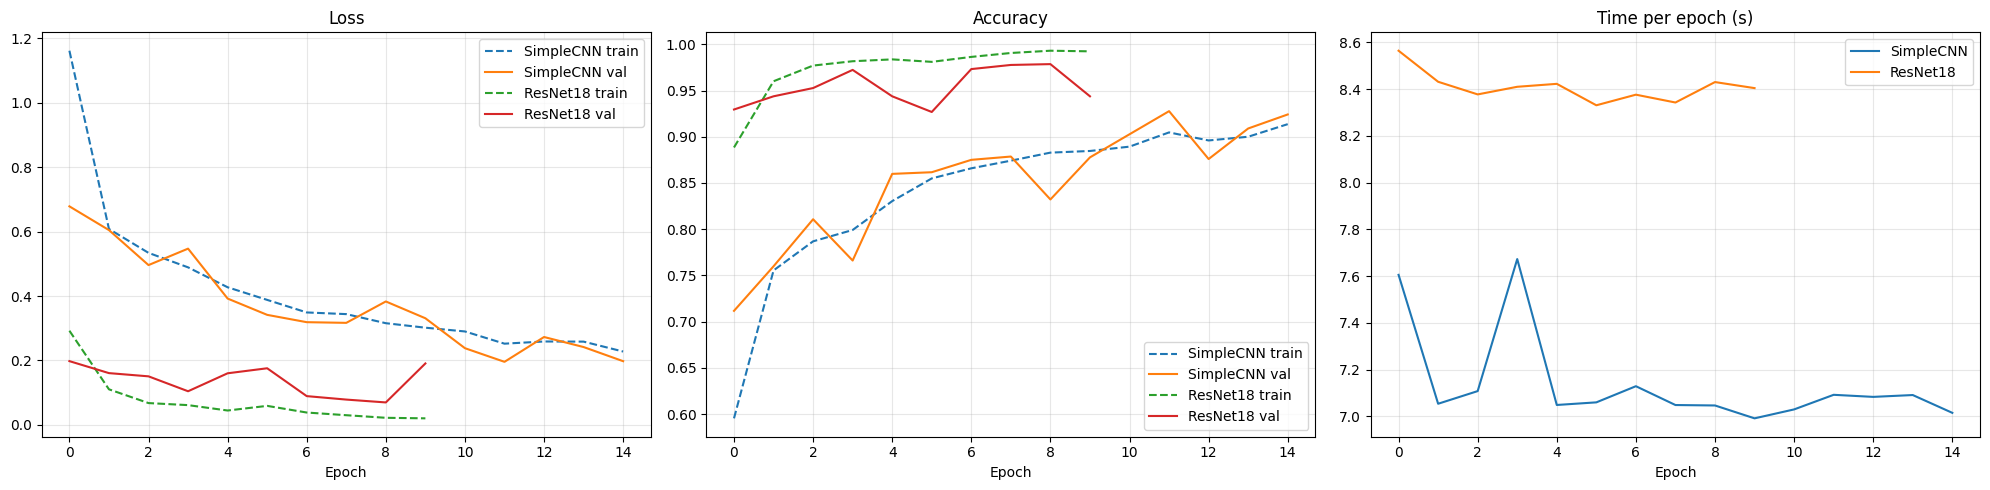

In [11]:
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for name, h in histories.items():
        axes[0].plot(h["train_loss"], "--", label=f"{name} train")
        axes[0].plot(h["val_loss"],   "-",  label=f"{name} val")
        axes[1].plot(h["train_acc"],  "--", label=f"{name} train")
        axes[1].plot(h["val_acc"],    "-",  label=f"{name} val")
        axes[2].plot(h["time"],       "-",  label=f"{name}")
    axes[0].set_title("Loss");     axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].grid(alpha=0.3)
    axes[2].set_title("Time per epoch (s)"); axes[2].set_xlabel("Epoch"); axes[2].grid(alpha=0.3)
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})

написала функцию full_report и вызвала её для обеих моделей на тестовой выборке. функция считает accuracy, печатает отчёт по каждому классу и рисует матрицу ошибок. в конце она возвращает accuracy и списки настоящих и предсказанных классов, они понадобятся для итоговой таблицы.


SimpleCNN — Test Accuracy: 0.8588
              precision    recall  f1-score   support

      glioma     0.9325    0.7250    0.8158       400
  meningioma     0.8016    0.7575    0.7789       400
     notumor     0.7791    0.9875    0.8710       400
   pituitary     0.9554    0.9650    0.9602       400

    accuracy                         0.8588      1600
   macro avg     0.8672    0.8587    0.8565      1600
weighted avg     0.8672    0.8588    0.8565      1600



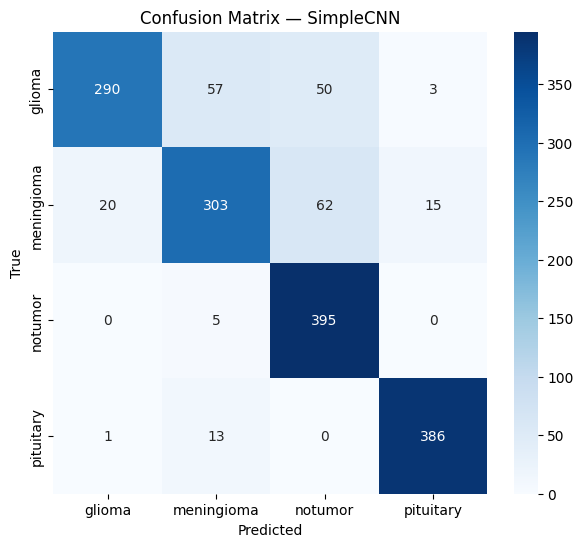


ResNet18 — Test Accuracy: 0.9437
              precision    recall  f1-score   support

      glioma     1.0000    0.7950    0.8858       400
  meningioma     0.8851    0.9825    0.9313       400
     notumor     0.9153    1.0000    0.9558       400
   pituitary     0.9950    0.9975    0.9963       400

    accuracy                         0.9437      1600
   macro avg     0.9489    0.9437    0.9423      1600
weighted avg     0.9489    0.9437    0.9423      1600



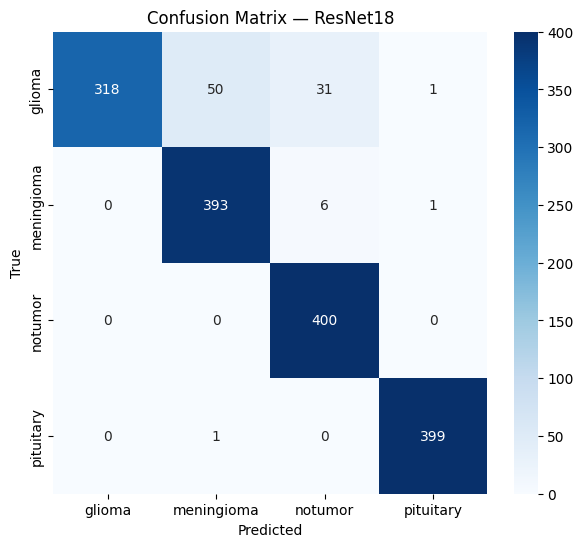

In [12]:
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = evaluate(model, loader, criterion)
    print(f"\n{'='*60}\n{title} — Test Accuracy: {acc:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred,
                                target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

res_cnn    = full_report(cnn_model,    test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

я написала две функции и собрала итоговую таблицу. count_params считает, сколько обучаемых параметров в модели. summarize берёт предсказания на тесте и считает средние precision, recall и f1 по всем классам (macro), а ещё собирает в одну строку число параметров, лучшую точность на val, точность на тесте, среднее время эпохи и число обученных эпох. потом я сложила строки обеих моделей в таблицу и вывела её через display.

In [13]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Params": f"{count_params(model):,}",
        "Best val acc": f"{max(hist['val_acc']):.4f}",
        "Test acc":     f"{res['acc']:.4f}",
        "Macro precision": f"{p:.4f}",
        "Macro recall":    f"{r:.4f}",
        "Macro F1":        f"{f:.4f}",
        "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
        "Epochs trained": len(hist["time"]),
    }

df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn,    res_cnn,    cnn_model),
    summarize("ResNet18",  hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
display(df_cmp)

,Params,Best val acc,Test acc,Macro precision,Macro recall,Macro F1,Mean epoch time (s),Epochs trained
Model,,,,,,,,
SimpleCNN,"2,339,972",0.9277,0.8588,0.8672,0.8587,0.8565,7.1,15
ResNet18,"11,178,564",0.9786,0.9437,0.9489,0.9437,0.9423,8.4,10


я написала функцию show_predictions, которая берёт 10 случайных снимков из теста и показывает, что предсказала модель. для каждого снимка функция применяет те же преобразования, что и при оценке, пропускает его через модель и переводит выход в вероятности через softmax. в заголовке написан настоящий класс, предсказанный класс и уверенность модели. если модель угадала, заголовок зелёный, если ошиблась, красный. функцию я вызвала для обеих моделей.

simplecnn. из 10 снимков модель угадала 9. одна ошибка на втором снимке в первой строке. настоящий класс glioma, а модель назвала его notumor с уверенностью 0.96.

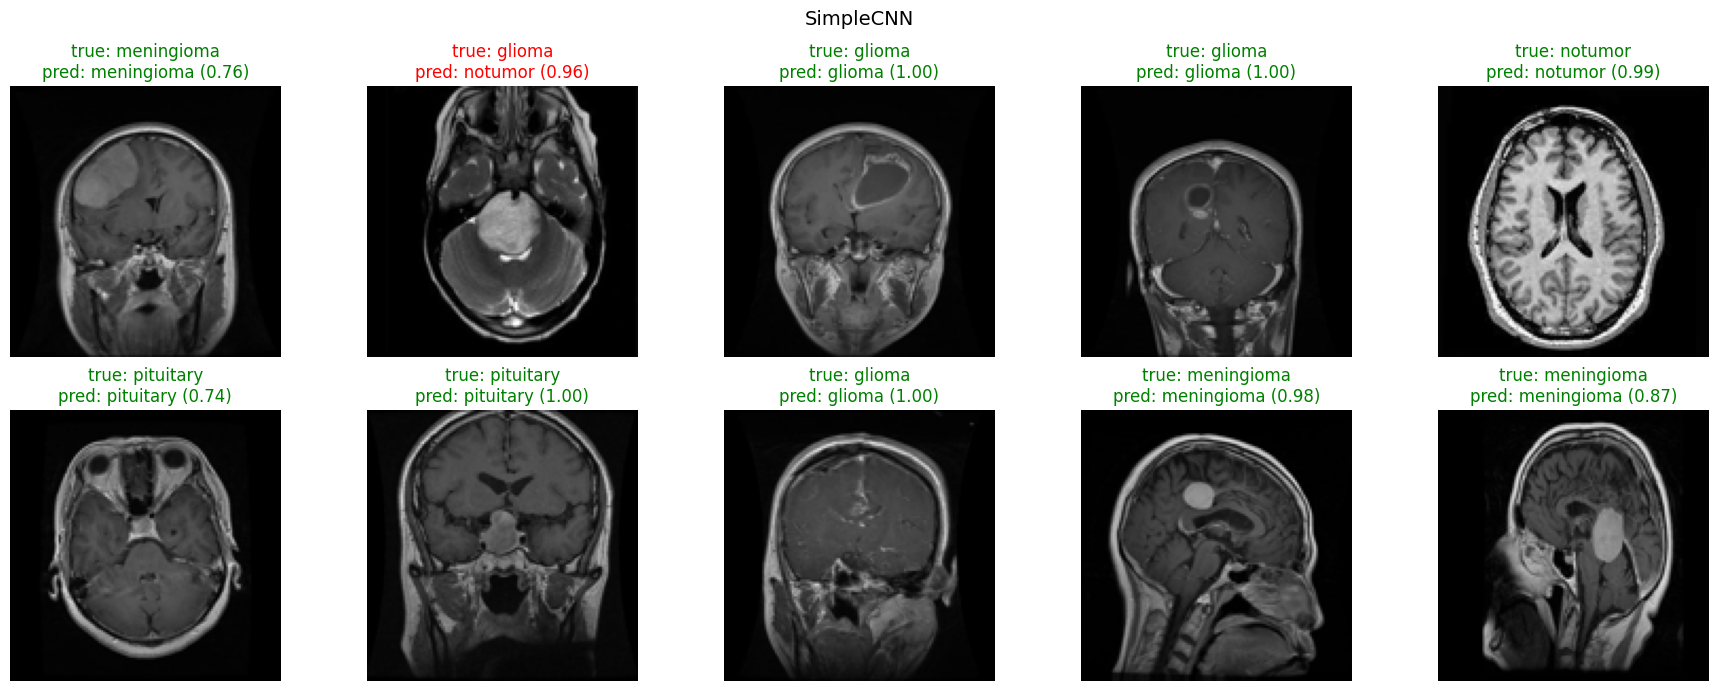

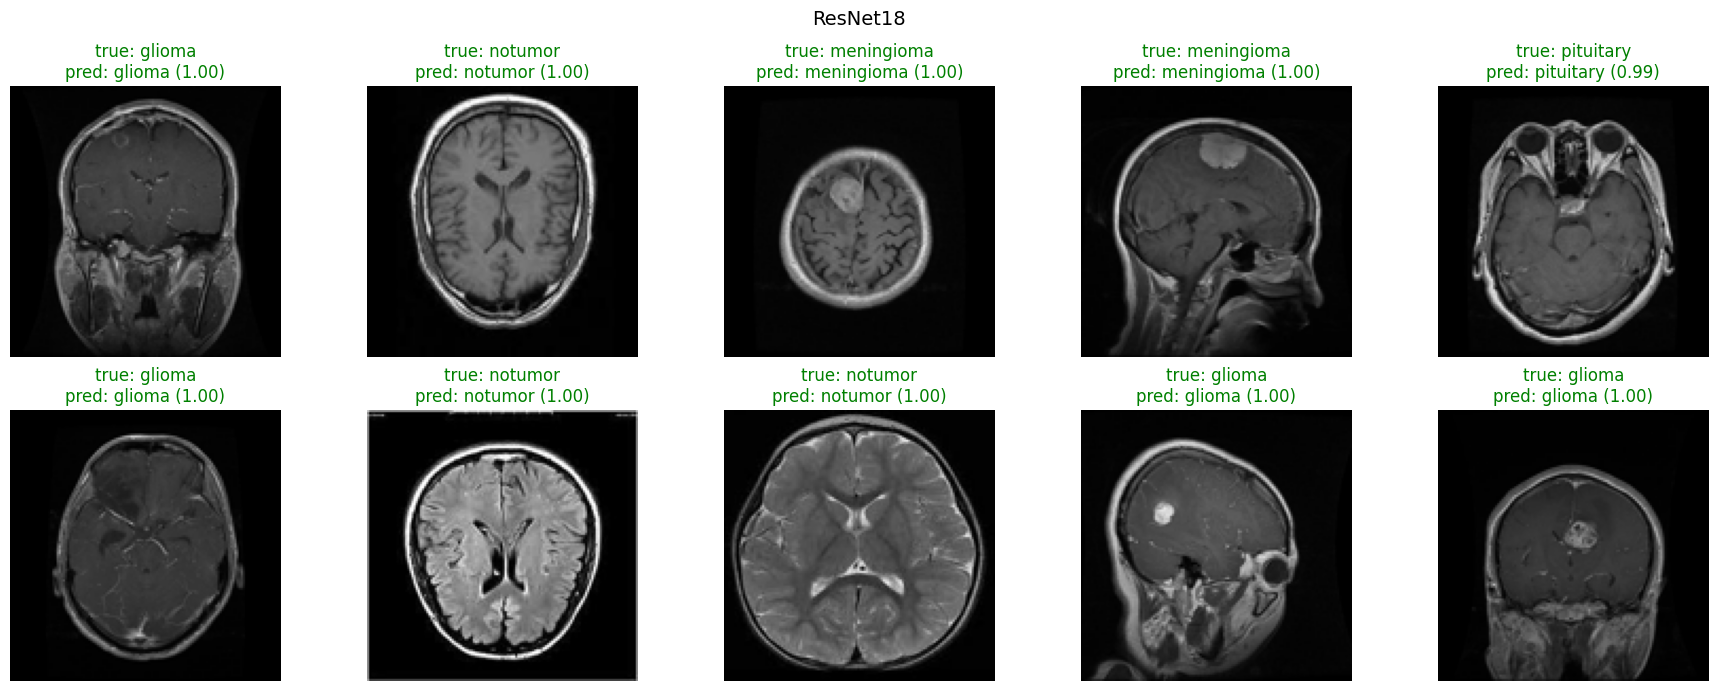

In [14]:
@torch.no_grad()
def show_predictions(model, images, labels, n=10, title="Model"):
    model.eval()
    idxs = np.random.choice(len(images), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(18, 7))
    for ax, i in zip(axes.ravel(), idxs):
        tensor = eval_tfms(images[i]).unsqueeze(0).to(device)
        prob = torch.softmax(model(tensor), dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))
        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"true: {class_names[labels[i]]}\n"
                     f"pred: {class_names[pred]} ({prob[pred]:.2f})",
                     color=color)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

show_predictions(cnn_model,    X_test, y_test_enc, n=10, title="SimpleCNN")
show_predictions(resnet_model, X_test, y_test_enc, n=10, title="ResNet18")